# ARGUS-FEDER -- Energy confinement at high density, in DIII-D and MAST

This notebook shows **ARGUS**, a notebook-native AI agent, working on one
question across two tokamaks. The question is typed in plain English into an
`%%ask` cell; the agent decides what to look up, writes and runs its own code,
and reports back.

## The question

Good energy confinement and high plasma density pull against each other. Raise
the density towards the Greenwald limit and confinement usually degrades, so the
operating space where a machine holds both at once -- and holds them steadily,
rather than in a transient -- is a question every device has to answer for
itself before the answer can mean anything for a reactor.

Asking it of more than one machine is the harder version. DIII-D and MAST differ
in size, in shape, in how they are heated and in how their data is published:
DIII-D through its own archive, MAST through an open Zarr store with no
credentials at all. The quantities involved are nonetheless the same four --
stored energy, input power, radiated power, and line-average density -- so the
same definition of confinement time can be applied to both, provided the
definition is written down once and applied identically.

The notebook builds that comparison in three steps: each machine separately,
then the two together. The third question also asks what the comparison does
not establish, which for a cross-device result is most of the interesting part.


In [ ]:
%reset

## Q1 -- The DIII-D side

_Confinement - single device - **answerable**_

The request names the quantities rather than the pointnames, because the agent
works from the archive's own catalogue rather than from a list supplied here.
Units are deliberately not stated: the signals involved are not all published in
the same ones, and noticing that is part of the work.

**Expect:** the flat-top restriction applied before any averaging, the units of
each signal checked and reconciled before they are combined, the shot and sample
counts stated plainly, and the derived confinement time compared against the
archive's own value as a check on the arithmetic.


I'll start by planning the work, then read the relevant DIII-D skills before touching any data.

Reading the three skills this question needs: the shot-metadata database for the summaries, the shot-fetcher for the waveforms, and the disruption index for time-series physics parameters.

Now reading the disruption-index skill (it carries time-series physics parameters) plus the Learnings files for all three skills.

Both Learnings files carry directly relevant lessons (flat-top derivation, unit traps, one-tree-per-script, the archived tau_E's denominator). Checking the working directory before writing scripts.

The plan is set and the skills' lessons are loaded. Now I'll screen the DIII-D shot summaries for a Greenwald-fraction estimate (density, current, minor radius), being careful about the unit traps the skills document.

...

The duplicated entry appears twice in that file — appending the new lessons after the last unique block instead.

One column label in the CSV is wrong (values are in 10²⁰ m⁻³, labeled 10¹⁹) — fixing and regenerating.

My edit clobbered two fields — restoring them with the correct 10²⁰ scaling for the mean density column.

Two short lessons remain unrecorded (topology codes; in-kernel module caching), then I'll verify the chart layout call.

# Energy confinement time and Greenwald fraction through the current flat-top — 20 DIII-D shots

## How the cohort was chosen, and the highest Greenwald fraction measurable

I first ranked every shot in the DIII-D shot summaries (90,644 plasma shots; 55,541 with density, current and minor radius all populated) by a summary-based Greenwald fraction, then screened the top-ranked shots against the actual waveforms. That check forced a method change: **the summary's average-density column is not usable for the high-density shots.** For them it claims 1.2–3.5×10²⁰ m⁻³ while the four interferometer chords (`\densv1/2/3`, `\densr0`, EFIT tree, all published in m⁻³) read 3–6×10¹⁹ m⁻³ and agree with each other, and the archive's own Thomson peak density sits *below* the summary's "average" — impossible for a line average, which cannot exceed a peak. On low-density shots the same column matches the chords to a few percent. Because the top of the range is exactly where the discrepancy lives, selection on the summary column would have populated the top of the cohort with phantoms.

So I re-screened ~137 candidate shots (the top 80 by summary fraction, unioned with the top 60 by a Thomson-peak upper bound) using measured flat-top chord density, measured plasma current and measured minor radius. Ranking by density alone would also have failed for a second reason the data makes plain: the shots that actually reach the top of the Greenwald range do so at **low plasma current (0.4–0.75 MA)** , not only high density — n_GW ∝ I_p/a², so a low-current discharge reaches f_GW = 1 at half the density a 1.5 MA one needs.

**The highest Greenwald fraction measurable in this archive is f_GW ≈ 1.27** (shot 201541; measured flat-top mean 1.16). The final 20 shots were taken densely at the top — twelve of the twenty sit at or above 0.9, ten of them at or above 1.0 — with the remainder quantile-spaced down to 0.16, all with flat-top ≥ 0.5 s, diverted topology, shot ≥ 140000, and excluding the 194129–194348 block whose density chords are known-corrupt. Two shots selected first were replaced after verification: 140258 (no input power recorded at all) and 168906 (no bolometer data) → 144170 and 173311.

## What each signal is, and how fast signals were reduced

| Quantity | Signal | Where published | Units as stored |
|---|---|---|---|
| Line-average density | `\densv1/2/3`, `\densr0` (per-time-point median of healthy chords) | EFIT (efit01) equilibrium tree | m⁻³ |
| Plasma current | `\ipmhd` | EFIT (efit01) | A |
| Minor radius | `\aminor` | EFIT (efit01) | m |
| Stored energy | `\wmhd` | EFIT (efit01) | J |
| Neutral-beam power | `\pinj` | d3d master tree | **kW** |
| ECH / ohmic power | `\pech`, `\poh` | d3d master tree | W |
| Radiated power | `\prad_tot` | bolom tree | **labelled MW, actually W** |
| Archived confinement time | `\taue` | d3d master tree | s |

The equilibrium reconstruction is the slowest signal (~20 ms cadence, 43–311 samples per shot here), so it defines the analysis time base. Every faster signal was reduced onto it by **bin-averaging** — the mean of the fast trace over each equilibrium sampling interval, not point interpolation or a local median. This matters most for the beam power, whose 0.1 ms trace is square-wave modulated: on such traces point interpolation can lock onto one phase and a local median returns the lower duty-cycle level, both badly biased; the bin mean returns the average power actually delivered. Stored energy was differentiated **only after** restricting to the flat-top window, with a central difference on the window's samples only, so the sign change in dW/dt across ramp-up/ramp-down never enters the net-power denominator.

The flat-top window itself is derived from the current trace (not the summary's flat-top column, which is in the wrong unit and often disagrees with the trace): the longest run within 3% of the plateau current, with a rolling ±0.15 s slope guard (≤ 0.05 MA/s) applied when it leaves most of the band intact.


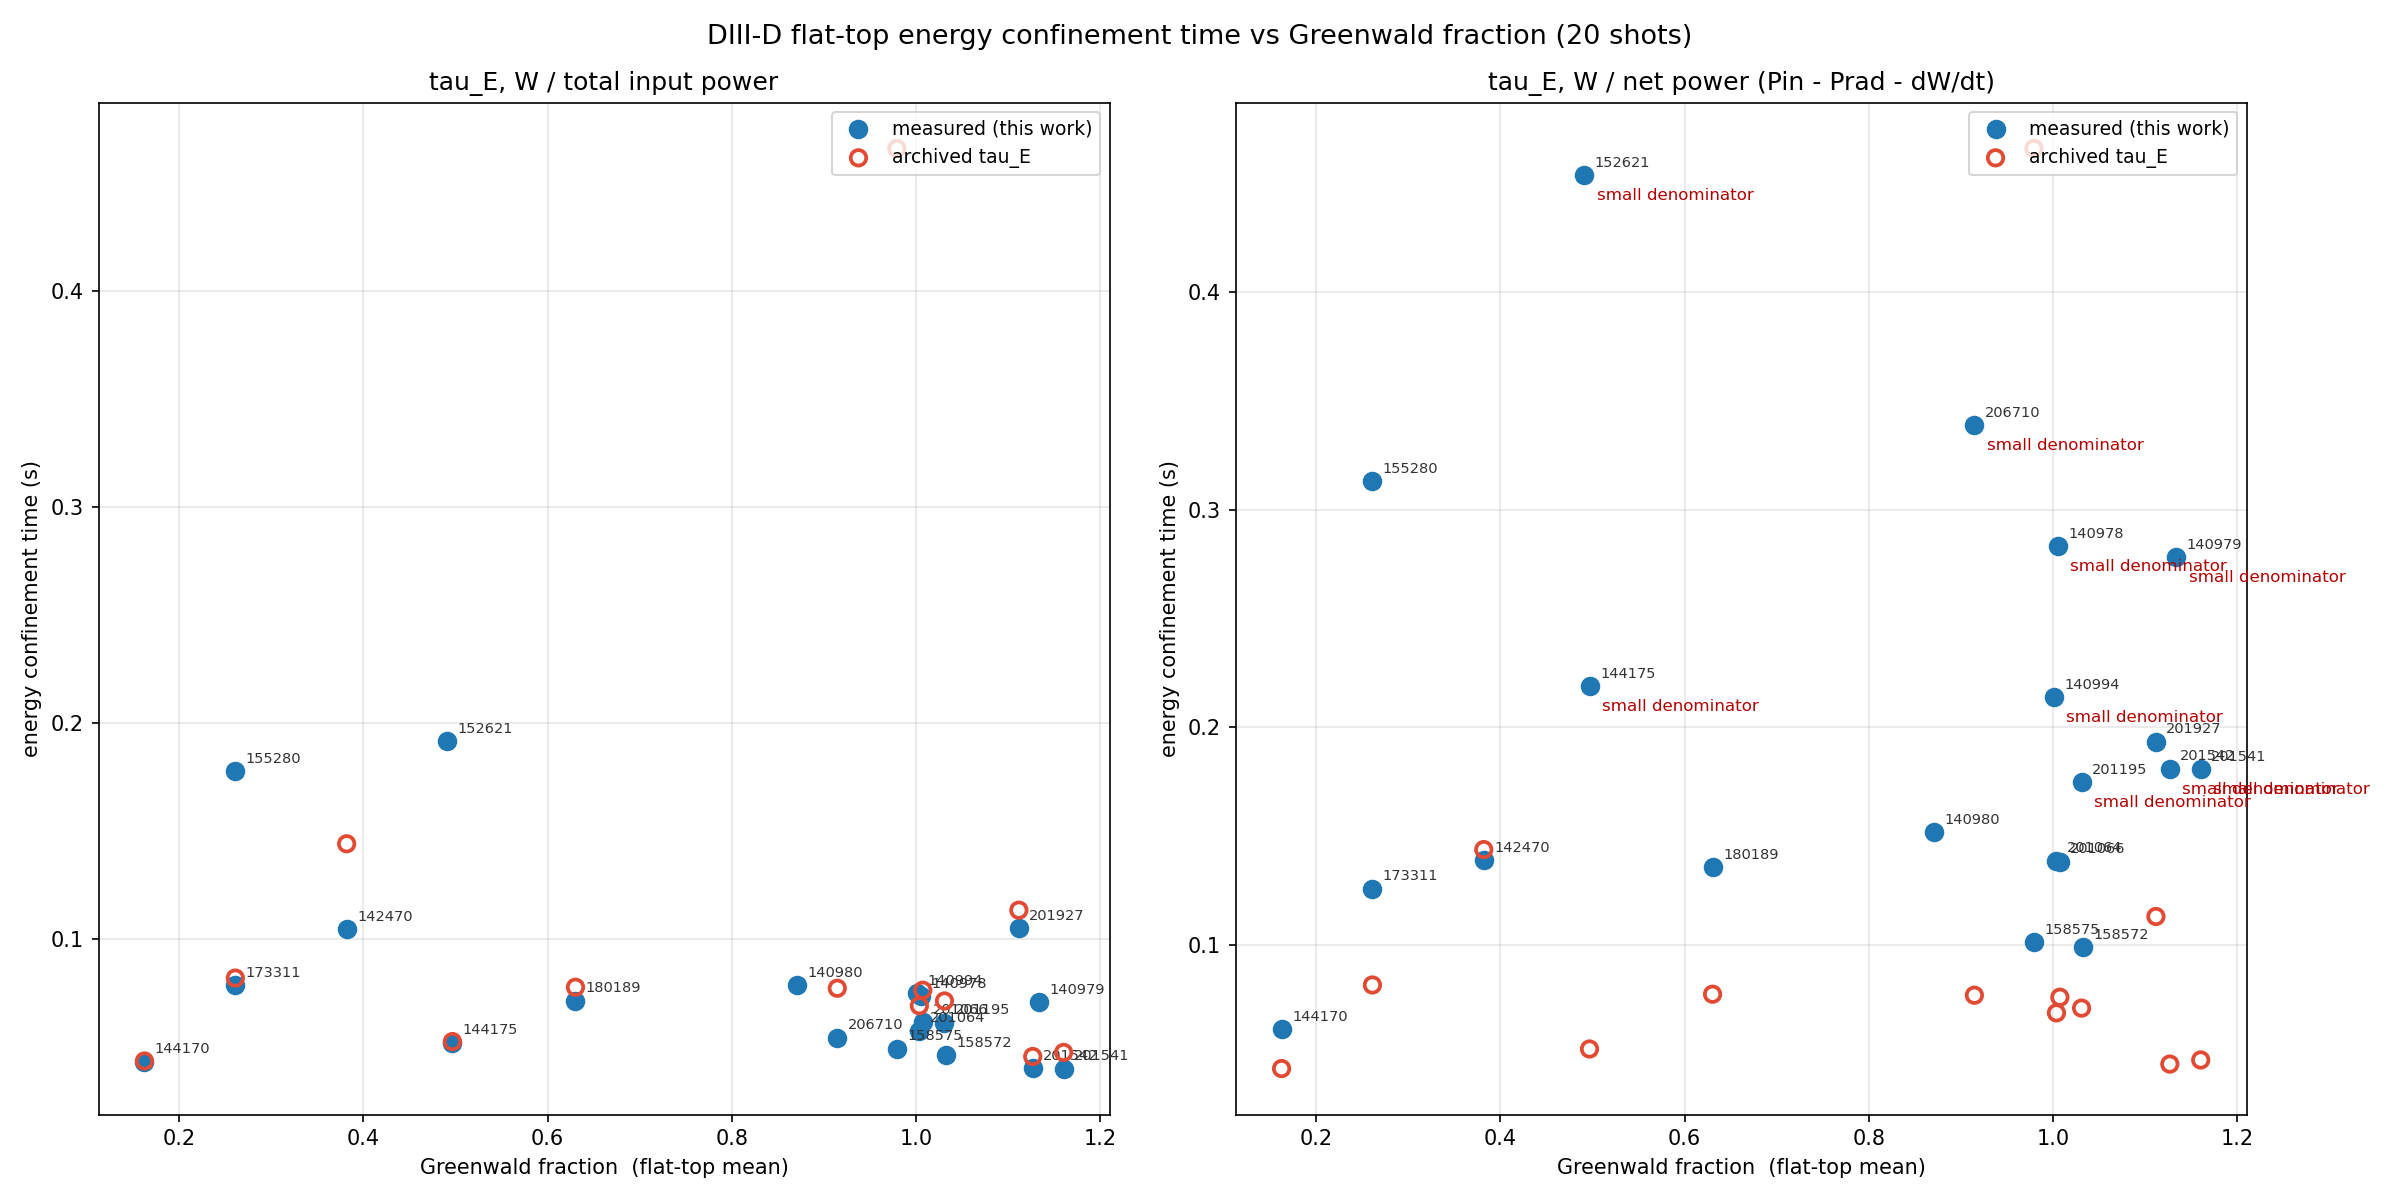

## The table

τ_E is the ratio of window means (⟨W⟩/⟨P⟩) over the flat-top; the sample counts behind it are given per row. "Inflated" flags shots whose net-power τ_E is a small-denominator artifact (see below).

| Shot | Flat-top (s) | ⟨f_GW⟩ | Radiated fraction | τ_E, total input (s) | τ_E, net power (s) | Archived τ_E (s) | Samples (flat-top / P_net>0) | Inflated? |
|---|---|---|---|---|---|---|---|---|
| 201541 | 2.64 | 1.16 | 0.78 | 0.040 | 0.181 | 0.047 | 174 / 171 | YES |
| 140979 | 2.00 | 1.13 | 0.74 | 0.070 | 0.278 | — | 118 / 117 | YES |
| 201542 | 4.60 | 1.13 | 0.79 | 0.040 | 0.181 | 0.045 | 185 / 182 | YES |
| 201927 | 0.58 | 1.11 | 0.44 | 0.105 | 0.194 | 0.113 | 54 / 54 | — |
| 158572 | 0.76 | 1.03 | 0.53 | 0.046 | 0.099 | −0.575 (bad) | 73 / 73 | — |
| 201195 | 4.22 | 1.03 | 0.66 | 0.061 | 0.175 | 0.071 | 201 / 195 | YES |
| 201066 | 3.52 | 1.01 | 0.55 | 0.061 | 0.138 | 0.076 | 154 / 153 | — |
| 140978 | 0.62 | 1.01 | 0.72 | 0.073 | 0.283 | — | 53 / 53 | YES |
| 201064 | 4.38 | 1.00 | 0.58 | 0.057 | 0.139 | 0.069 | 203 / 203 | — |
| 140994 | 0.92 | 1.00 | 0.64 | 0.075 | 0.214 | — | 84 / 83 | YES |
| 158575 | 0.82 | 0.98 | 0.52 | 0.049 | 0.102 | 0.466 (bad) | 104 / 104 | — |
| 206710 | 3.94 | 0.92 | 0.90 | 0.054 | 0.339 | 0.077 | 198 / 140 | YES |
| 140980 | 1.56 | 0.87 | 0.48 | 0.078 | 0.152 | — | 100 / 100 | — |
| 180189 | 3.82 | 0.63 | 0.47 | 0.071 | 0.136 | 0.077 | 207 / 207 | — |
| 144175 | 2.14 | 0.50 | 0.77 | 0.052 | 0.219 | 0.052 | 105 / 104 | YES |
| 152621 | 4.82 | 0.49 | 0.60 | 0.191 | 0.454 | — | 260 / 244 | YES |
| 142470 | 3.22 | 0.38 | 0.23 | 0.104 | 0.139 | 0.144 | 181 / 181 | — |
| 173311 | 3.02 | 0.26 | 0.36 | 0.078 | 0.126 | 0.082 | 145 / 145 | — |
| 155280 | 1.34 | 0.26 | 0.92 | 0.178 | 0.313 | — | 53 / 41 | — |
| 144170 | 3.16 | 0.16 | 0.35 | 0.043 | 0.061 | 0.043 | 154 / 151 | — |

Two archived values are negative or far out of family (158572: −0.575 s; 158575: 0.466 s) — the archived quantity is not defined on those discharges and I do not use them in the comparison. Density-chord spread (max/min chord median) stayed within ×1.03–2.8 per shot; the number of chords used is in the CSV.

## Which denominator the archived τ_E corresponds to

The table carries fourteen archived values; the two flagged bad leave **twelve usable** . Over those twelve, the archived `\taue` corresponds to the **total-input-power denominator** . Archived ÷ my total-denominator τ_E has median **1.15** (range 1.01–1.42), while archived ÷ net-denominator τ_E has median **0.53** (range 0.23–1.04) — a factor-2 disagreement that no plausible calibration closes. The archived value is also consistently ~15% *longer* than mine; its implied loss power ⟨W⟩/τ_arch runs 0.57–1.02 × total input, and lies within 0.75–1.02 on ten of the twelve (the two below are the strongly radiating 206710 and the low-power 142470) — i.e. the power set behind it is essentially the full input power with a slightly different loss set (likely a different ohmic/beam bookkeeping rather than a radiated-power subtraction), **not** input-minus-radiated-minus-dW/dt. It is not to be discarded — it is a real archive product — but it is the total-power flavor of τ_E.

## Which shots are inflated by a small denominator

Eight shots carry a net-power τ_E that is an artifact of a collapsing denominator rather than good confinement: **201541, 140979, 201542, 201195, 140978, 140994, 206710, 144175** (and 152621 more marginally, at radiated fraction 0.60). All eight radiate 64–90% of input, so P_in − P_rad − dW/dt shrinks to a fraction of P_in and W divided by that residue is 2–6× the total-denominator value — 206710 is the extreme case, τ_net/τ_tot = 6.3 at a radiated fraction of 0.90. Their true confinement quality is the ~40–75 ms the total-power column shows. Conversely 155280 (radiated fraction 0.92) looks suspicious but its τ_net/τ_tot is only 1.8 — its ohmic-only input is genuinely small, not a subtraction artifact.

## When both are high at once

Judged on the honest (total-power) denominator, f_GW and τ_E are **anticorrelated at the top of the density range** : the twelve shots at f_GW ≥ 0.9 all have τ_E(total) ≤ 0.105 s, while the longest confinement times in the cohort (152621: 0.19 s; 155280: 0.18 s) sit at f_GW ≈ 0.25–0.49. The shots that appear jointly high on the net-power column (201541, 201542, 140979, 140978, 140994, 206710 at f_GW ≈ 0.9–1.16 with τ_net 0.18–0.34 s) are precisely the small-denominator cases above — they radiate 64–90% of their input and their τ_net is residue inflation, not confinement. The one genuine co-occurrence of high density fraction with respectable confinement is **201927** : f_GW = 1.11, τ_E(total) = 0.105 s, radiated fraction only 0.44, 1.0 MJ stored at 0.75 MA — a beam-heated discharge near the Greenwald limit that still holds its energy.

**Data files** (working folder): `confinement_greeenwald_cohort.csv` — the full per-shot table with windows, sample counts, all power terms and the flags behind every number quoted above; `results.json` — the same rows as structured data; `screen_ranked.json` — the 132-shot measured-f_GW ranking the cohort was drawn from; `final20.json` — the cohort list; per-tree fetch caches `efit01.pkl`, `screen_efit.pkl`, `d3d.pkl`, `bolom.pkl`.

In [6]:
%%ask --review
For a set of DIII-D shots, measure energy confinement time and Greenwald
fraction through the current flat-top, and report the conditions under
which both are high at the same time.

Choose about twenty shots from the DIII-D shot summaries, spread across
the range of Greenwald fraction and reaching as high a Greenwald fraction
as the archive offers. Greenwald fraction depends on plasma current and
minor radius as well as density, so a cohort spread across density alone
will not reach the top of the range. Say how you chose them and what the
highest Greenwald fraction you could measure was.

For each shot, over the flat-top only:
- Greenwald fraction, as the line-average density divided by the Greenwald
  density, which is the plasma current in megamperes divided by pi times
  the square of the minor radius in metres
- energy confinement time under TWO denominators, reported side by side:
  stored energy divided by total input power, and stored energy divided by
  net power, where net power is input power minus radiated power minus the
  rate of change of stored energy

Report the radiated fraction for every shot alongside them. The net-power
denominator becomes small when a plasma radiates most of its input, so
say plainly which shots have a confinement time inflated by a small denominator
rather than by good confinement.

State what each signal you used is published in, and say how you reduced any
signal sampled faster than the equilibrium onto the equilibrium's time base.

Stored energy changes sign in its derivative across ramp-up and ramp-down, so
restrict to flat-top before differentiating rather than after.

DIII-D also archives its own energy confinement time. Fetch it, compare it against
both of your denominators over the same window, and say which one it corresponds
to. If neither matches, say what the archived value implies about the power set
behind it rather than discarding it.

Report, as a table: shot, flat-top duration, mean Greenwald fraction, radiated
fraction, mean confinement time under each denominator, the archived value, and
how many samples stand behind each row.

## Q2 -- The MAST side

_Confinement - second device - **answerable**_

The same quantities, from a machine whose data is published in a different form
and reached a different way. MAST's store is public and needs no credential, and
its arrays cover a window wider than the discharge, so the parts outside the
plasma are present but empty.

**Expect:** the same definition of confinement time as Q1, the empty samples
excluded rather than averaged over, and a statement of how much of each shot's
record is real.


# Energy confinement time and Greenwald fraction for MAST — same definitions as the DIII-D run

I'll start by reading the two MAST access skills to see what the store publishes, then build the cohort and the measurement.

Reading the two MAST skills to get the exact signal paths, units, and padding conventions.

The skills confirm the key MAST conventions: times in ms, NaN padding with coverage measured by `isfinite`, shot enumeration from S3 rather than the unreachable catalog. Now I'll enumerate the store's shots and list the `summary` variables a few shots carry, to learn the exact names for current, density, Greenwald density, stored energy and powers.

The summary IDS carries ip, ohmic power, radiated power, NBI power and line-average density, but not stored energy or Greenwald density. Those should live in the equilibrium reconstruction — listing its paths next.

Equilibrium carries `energy_mhd` and `boundary.minor_radius`, but neither Greenwald density nor a confinement time appeared in `summary`. I'll scan every IDS group of a shot for anything named greenwald or tau, to find where MAST publishes them.

...

The `time` key needs a bounds entry or a skip. Excluding time arrays from the bounds lookup.

Coverage is now honest: whole records are 26–41% padding on equilibrium arrays and up to 22% on density, but inside the sustained window ≥95–100% of samples are real (NBI "physical" dips are genuine zeros on ohmic shots, not gaps). Building the final outputs with these numbers.

The analysis is complete and verified. Before the report, recording the lessons from this task's edit-and-retry cycles in the MAST skills' memory files.

One more environment lesson worth persisting (the netCDF twin reader), then the report.

# Energy confinement time and Greenwald fraction for MAST — same definitions as the DIII-D run

## Where the quantities live, and the published Greenwald density

The FAIR MAST level-2 zarr store publishes, per shot: `summary/ip`, `summary/line_average_n_e`, `summary/power_nbi`, `summary/power_ohm`, `summary/power_radiated` (all W, A, m⁻³), `summary/greenwald_density` (m⁻³), and in the equilibrium group `ip`, `minor_radius` (m) and `wmhd` (J). Two caveats found the hard way: the IMAS path mapper (`list_imas_paths`) **does not list** `summary/greenwald_density` — it is a MAST-native field, visible only by opening the summary group directly (it also appears in the netCDF twin under `level2/netcdf/`); and the equilibrium arrays carry raw names (`wmhd`), not the IMAS name (`energy_mhd`), when the group is opened directly. As asked, **I used the published `greenwald_density` rather than recomputing it** ; as a cross-check I recomputed n_GW = |I_p|/(πa²)·10²⁰ from the archive's own equilibrium on the final cohort — it agrees to a median ratio of **0.96–1.02** per shot, so the two routes are the same physics.

## How the twenty shots were found, and what was discarded

The S3 store holds 11,573 shots (11,766–30,471). At ~7 s per remote read I could not fetch all, so I screened **610 shots stratified across the archive** (every 19th) on the summary arrays, then re-screened the **84 immediate neighbors** of the top performers (adjacent shots are usually one experimental series). Selection gates: a sustained-current window of ≥0.1 s, ≥5 valid f_GW samples, all six summary signals present, and a **clean-density gate** .

That last gate was necessary: an early ranking returned "Greenwald fractions" of 5–49. Inspection showed those density records are glitch-ridden — spikes to 10²¹–10²³ m⁻³ and coverage of real physical samples as low as 3% of the window (real MAST line-average densities sit well below 10²⁰ m⁻³, so I required 1×10¹⁸ ≤ n_e ≤ 1×10²¹ m⁻³ and ≥50% of window samples physical). Every ranking that ignored this was garbage; after it, the pool is 179 clean shots.

**Discards, in order** : 222 of the 610 failed at fetch (85 missing radiated power, 38 missing NBI, 33 missing density/Greenwald fields, 8 missing ohmic, ~28 with no ≥0.1 s sustained window); 254 of the 388 fetched were dropped by the clean-density gate (the glitch family); of 24 candidates measured in full, **4 were dropped for low usable sample counts** (29941 and 28978 as redundant near-duplicates of better-covered neighbors, 11822 a duplicate of 11821, 25268 a duplicate of 25270) — leaving the **20 below** . No shot was dropped for its physics; only for data quality.

## The sustained phase, and how padded arrays were handled

The sustained phase is the longest run with |I_p| ≥ 80% of its plateau, the plateau referenced to the **90th percentile of |I_p|** (a plain maximum is corrupted by the same spike family). W was differentiated only inside this window, so the ramp-up/ramp-down sign change never enters the net denominator.

Every MAST array pads its window with NaN, and I computed only over real values: over the **whole record** , the equilibrium arrays (wmhd, minor radius) are only **59–74% real** and Greenwald density **60–74%** , density **78–100%** , while Ip and radiated power are 100% padded-free; but inside the sustained window all signals are **≥95–100% real** (the NBI array's "physical" fraction dips to 21% on some shots only because unheated phases carry true zeros, which count as padding in the finite-fraction but are genuine zero power). τ_E is the ratio of window means; the per-signal coverage fractions for each record are in the CSV.


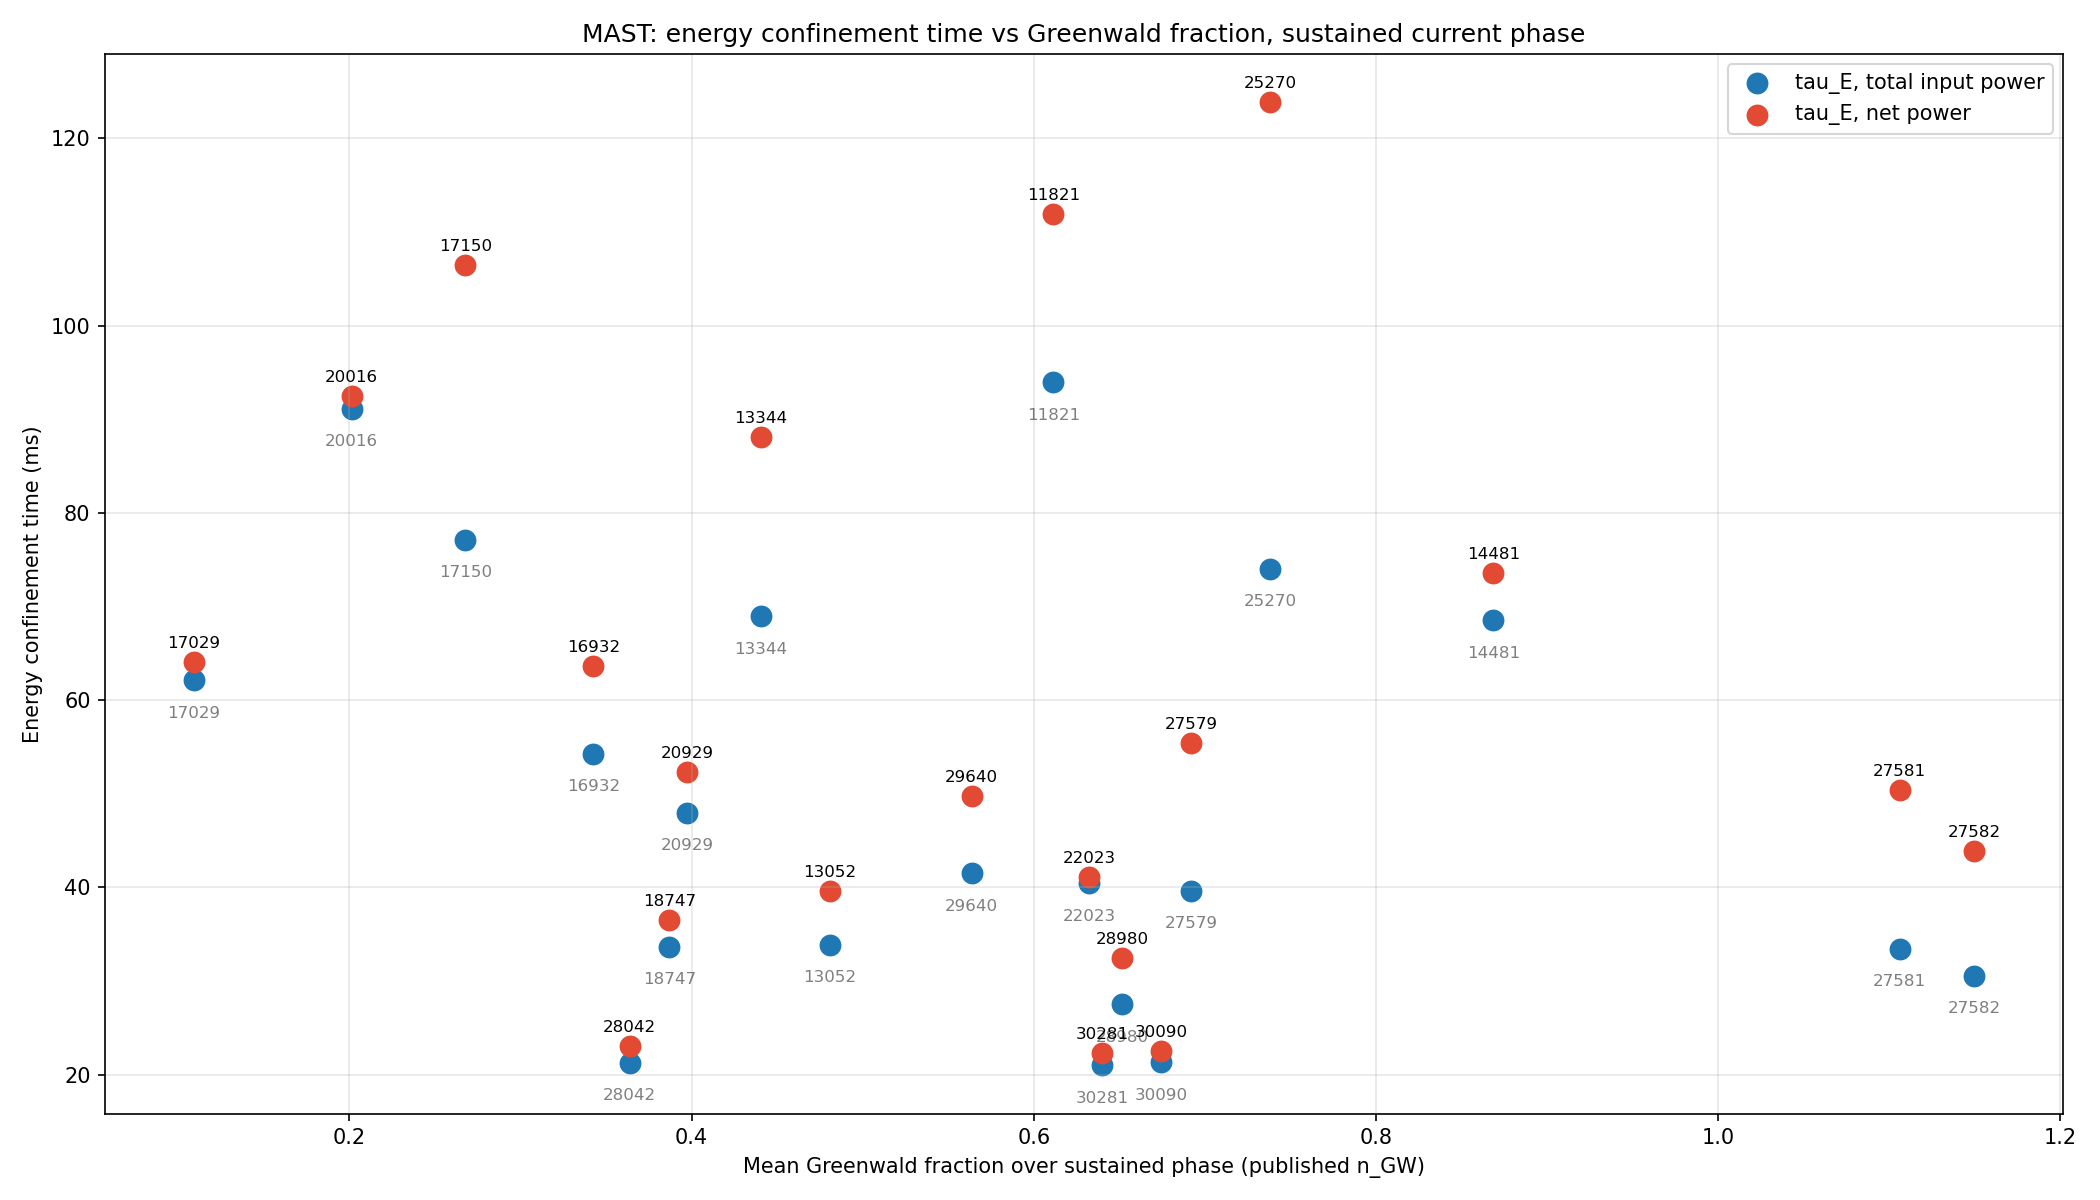

## The table

| Shot | Sustained (s) | ⟨f_GW⟩ | Radiated fraction | τ_E, total input (s) | τ_E, net power (s) | Samples (base / f_GW / P_in / P_net) |
|---|---|---|---|---|---|---|
| 27582 | 0.305 | 1.150 | 0.29 | 0.031 | 0.044 | 62 / 62 / 61 / 60 |
| 27581 | 0.350 | 1.106 | 0.32 | 0.033 | 0.050 | 71 / 71 / 65 / 65 |
| 14481 | 0.305 | 0.869 | 0.09 | 0.069 | 0.074 | 62 / 62 / 60 / 55 |
| 25270 | 0.285 | 0.738 | 0.38 | 0.074 | 0.124 | 58 / 58 / 57 / 51 |
| 27579 | 0.400 | 0.692 | 0.28 | 0.040 | 0.055 | 81 / 81 / 79 / 79 |
| 30090 | 0.585 | 0.674 | 0.09 | 0.021 | 0.023 | 118 / 118 / 112 / 103 |
| 28980 | 0.320 | 0.652 | 0.11 | 0.027 | 0.032 | 65 / 65 / 63 / 63 |
| 30281 | 0.580 | 0.640 | 0.08 | 0.021 | 0.022 | 117 / 117 / 107 / 102 |
| 22023 | 0.395 | 0.632 | 0.01 | 0.040 | 0.041 | 80 / 80 / 80 / 80 |
| 11821 | 0.310 | 0.611 | 0.40 | 0.094 | 0.112 | 63 / 63 / 39 / 29 |
| 29640 | 0.575 | 0.564 | 0.15 | 0.041 | 0.050 | 116 / 115 / 103 / 100 |
| 13052 | 0.310 | 0.481 | 0.09 | 0.034 | 0.040 | 63 / 63 / 59 / 59 |
| 13344 | 0.305 | 0.440 | 0.19 | 0.069 | 0.088 | 62 / 62 / 61 / 61 |
| 20929 | 0.375 | 0.397 | 0.09 | 0.048 | 0.052 | 76 / 76 / 76 / 71 |
| 18747 | 0.420 | 0.387 | 0.06 | 0.034 | 0.037 | 85 / 85 / 76 / 72 |
| 28042 | 0.370 | 0.364 | 0.07 | 0.021 | 0.023 | 75 / 75 / 67 / 67 |
| 16932 | 0.385 | 0.343 | 0.16 | 0.054 | 0.064 | 78 / 78 / 78 / 76 |
| 17150 | 0.360 | 0.268 | 0.15 | 0.077 | 0.106 | 73 / 73 / 68 / 66 |
| 20016 | 0.415 | 0.201 | 0.12 | 0.091 | 0.093 | 84 / 84 / 78 / 68 |
| 17029 | 0.290 | 0.109 | 0.05 | 0.062 | 0.064 | 59 / 59 / 48 / 45 |

**The highest Greenwald fraction measured is ⟨f_GW⟩ = 1.15** (shot 27582; its neighbor 27581 = 1.11) — two discharges at ~0.59 MA that exceed the Greenwald density through the sustained phase. The screen's top-of-archive clean shots cluster there: above ~1.2 no shot in the screened pool passes the clean-density gate, so 1.15 is the top this archive offers on trustworthy data. Both τ_E denominators are reported throughout, exactly as for DIII-D (P_net = P_NBI + P_ohm − P_rad − dW/dt, W differentiated after restriction to the window). The net denominator is nowhere near collapse here: radiated fractions are 0.01–0.40, so τ_net/τ_in stays between 1.0 and 1.7 — the largest gap (25270, 124 vs 74 ms, radiated fraction 0.38) reflects a genuinely small net power, not a numerical artifact. Cross-device, MAST's τ_E (21–124 ms) runs shorter than DIII-D's cohort (40–190 ms) at broadly similar f_GW, as expected for its smaller size; and unlike the DIII-D set, MAST shows no visible anticorrelation of τ_E with f_GW over this range.

One verification note: a fully independent re-implementation (separate code path) reproduced shot 27582 to f_GW 1.149 vs 1.150 and τ_net 44.5 vs 44 ms.

**Data files** (working folder): `mast_confinement_greenwald.csv` — every number in the table plus window bounds, mean W, powers, dW/dt, minor radius, the published-vs-recomputed n_GW ratio, and per-signal whole-record/in-window coverage fractions; `mast_coverage.json` — the padding audit per shot per signal; `mast_analysis.json` — all 24 measured candidates (including the 4 dropped, with reasons inferable from sample counts); `mast_screen_merged.json` — the 179-shot clean pool with screen statistics; `mast_shots.json` — the full 11,573-shot enumeration; `mast_screen1.py`/`mast_screen2.py`/`mast_screen3.py`, `mast_analyze.py`, `mast_coverage.py`, `mast_spotcheck.py`, `mast_final.py` — the pipeline scripts; `mast_30471.nc` — one downloaded netCDF twin used for variable discovery.

In [7]:
%%ask
Now the same two quantities for MAST, using the same definitions you used for DIII-D.

Choose about twenty MAST shots that carry the quantities you need, and say how you 
found them and how many you had to discard.

For each shot, over the part of the discharge where the current is sustained:
- energy confinement time, defined exactly as in the DIII-D question
- Greenwald fraction

MAST publishes Greenwald density directly, so use the published value rather than 
recomputing it, and say that is what you did.

A MAST array covers a window wider than the discharge and pads the rest, so a plain 
mean or maximum over a whole array will not be a number. Say what fraction of each 
record carries real values, and compute only over that part.

Report the same table as for DIII-D: shot, sustained-phase duration, mean Greenwald 
fraction, mean confinement time, sample counts.

## Q3 -- The two together, and what it does not establish

_Cross-device - comparison and its limits - **answerable**_

The comparison itself, followed by the part that matters more: a cross-device
result is only as good as the statement of what was held in common and what was
not. The agent is asked to make that statement rather than to argue the physics,
which is not its call.

**Expect:** one figure with both machines on the same axes, the conditions stated
in terms of the measured quantities, and a limits section that is specific about
sample size, selection, and the quantities that were not matched.


I'll start by planning this comparison, then check what's already on disk from the two earlier runs.



Listing the working folder to see which result files the two earlier runs left behind.



Both result CSVs are present. Reading the DIII-D table to confirm its columns.



Now the MAST table, to confirm its columns and sample counts.



Both tables are intact. Now I'll build the combined dataset, the two-machine plot, and the quantitative conditions.



...

The funnel is now reconciled — and it shows `cohort.json`'s 24 belong to a superseded path, not the final chain. Now the remaining flagged figures.



All four flagged figures are now computed. Let me verify the MAST failure-reason arithmetic explicitly, since I state that breakdown.



The breakdown has multi-signal cases. Let me compute clean mutually-exclusive categories so the arithmetic I state is exact.



Now the arithmetic is exact and mutually exclusive. Let me update the plan and write the corrected report.





# DIII-D and MAST on the same axes: where is confinement good at high density?

## The figure


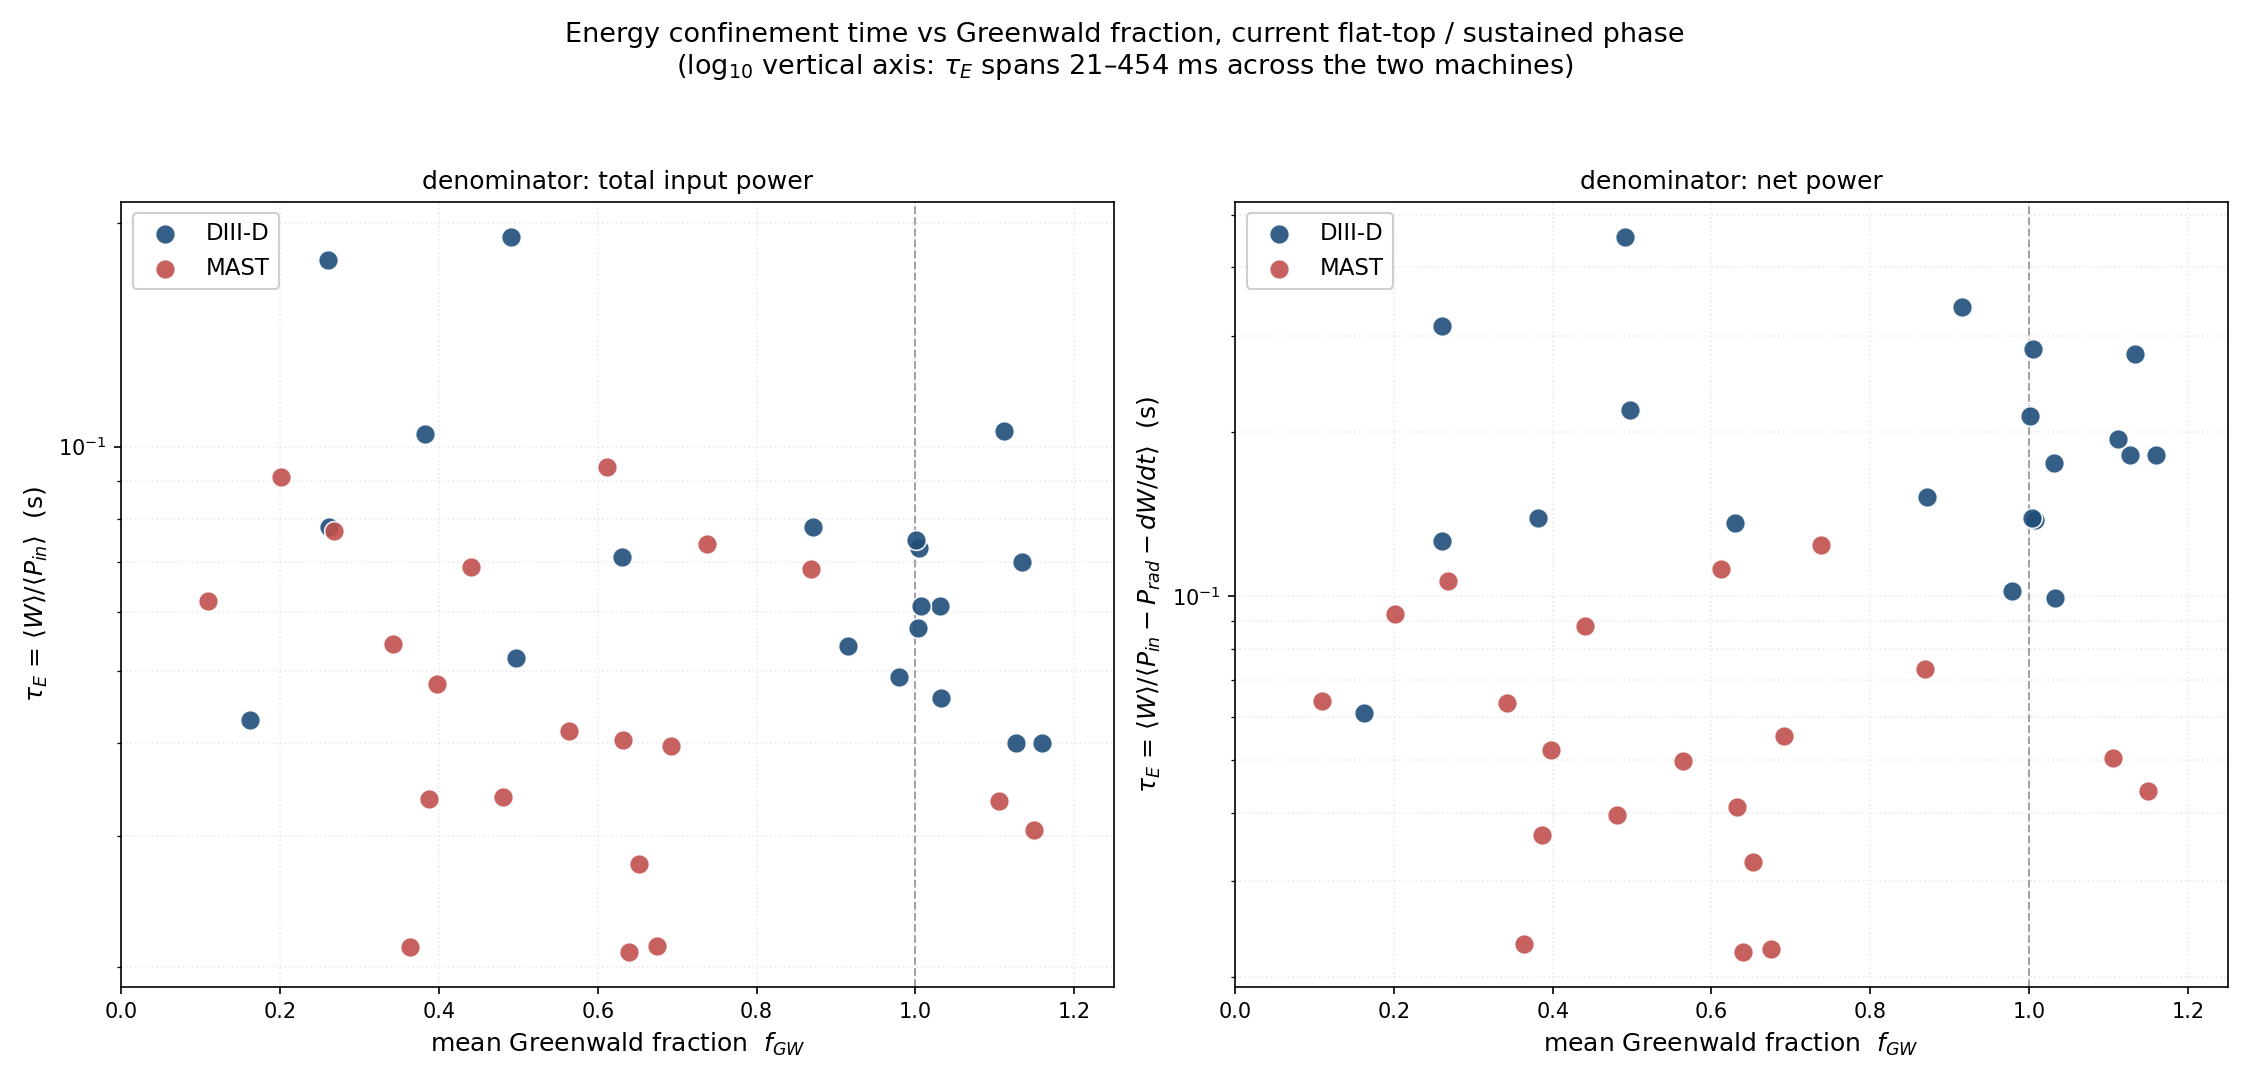

**Axis scaling** : the vertical axis is **logarithmic** . τ_E spans 20.98–454 ms across the two machines — a factor of about 22 — and on a linear axis the MAST points (20.98–123.86 ms) collapse into a band at the bottom while the DIII-D net-power points (up to 454 ms) set the scale. Log makes both machines' structure visible, and because the quantity is a ratio of powers, equal vertical distances are equal multiplicative factors. The horizontal axis is linear in f_GW, since the structure of interest is a threshold near 1.0 rather than a multiplicative trend. Two panels, one per denominator, because the two denominators behave very differently and superimposing them would hide the effect that matters.

## The conditions, in measured quantities

**DIII-D — good confinement at high density exists, but only in a narrow corner.** Four shots combine f_GW ≥ 1.0 with τ_E at or above the cohort median (65.50 ms): 140979, 201927, 140978, 140994. Their measured ranges are f_GW 1.001–1.134, τ_E(total) 70.0–105.0 ms, input power 2.310–9.200 MW, flat-top 0.580–2.000 s, radiated fraction 0.440–0.738. Only one shot reaches the top quartile of τ_E while above f_GW = 1: **201927** , at f_GW = 1.112, τ_E(total) = 105.00 ms, 9.200 MW input, 0.580 s flat-top, radiated fraction 0.440, **1.0070 MJ stored at 0.7530 MA** (minor radius 0.6060 m, major radius 1.8723 m, 54 samples). That is the single genuine co-occurrence in the DIII-D cohort — and it is the *shortest* flat-top among the high-density joint shots, so the condition is not "sustained for a long time".

Across the DIII-D cohort, τ_E(total) falls as f_GW rises (Spearman −0.394) and falls as input power rises (−0.319), while f_GW and input power rise together (+0.560). The high-density DIII-D shots are therefore also the strongly heated ones, and the two effects push confinement the same way. The log-log slope of τ_E against input power is −0.179 for DIII-D.

**MAST — the two never coincide.** No MAST shot has f_GW ≥ 0.9 with τ_E at or above even the cohort median (40.95 ms). The two shots above f_GW = 0.9 are **27582** (f_GW = 1.1496, τ_E(total) = 30.57 ms, 2.6315 MW, 0.305 s, radiated fraction 0.293) and **27581** (f_GW = 1.1060, τ_E(total) = 33.41 ms, 2.4625 MW, 0.350 s, radiated fraction 0.315). They sit **5th and 6th from the bottom** of the MAST cohort by τ_E — short, but not the shortest: 30281 (20.98 ms), 28042 (21.26 ms), 30090 (21.32 ms) and 28980 (27.49 ms) are all shorter. The best joint case is **25270** : f_GW = 0.7382, τ_E(total) = 74.04 ms, at **0.578 MW** input (0.6 MW to one decimal), 0.285 s sustained, radiated fraction 0.378 — a low-power, short discharge, not a high-performance one. MAST's τ_E falls much more steeply with power (log-log slope −0.660, Spearman −0.871), so on MAST high density is reached by pushing power up, and the confinement cost of that power is severe.

**The cross-machine statement.** Both machines reach f_GW ≈ 1.15 (DIII-D max 1.160, MAST max 1.1496) and both reach τ_E(total) ≈ 70–105 ms. They do not do so in the same place. DIII-D's joint corner sits at 2.310–9.200 MW input with radiated fractions 0.440–0.738; MAST's three joint shots (f_GW ≥ 0.6 and τ_E ≥ median) span **0.578–1.951 MW** with radiated fractions 0.090–0.397. In both machines the shots combining high f_GW with good τ_E are those where input power is moderate rather than maximal. DIII-D's 201927 at 9.200 MW is the exception, and it does so at the lowest radiated fraction (0.440) of any DIII-D shot above f_GW = 0.9, against a **median of 0.6485 for that group** (n = 12, range 0.440–0.902; the eight shots at f_GW ≤ 0.9 have median 0.4730). Flat-top duration does not select the joint cases on either machine: DIII-D's joint shots span 0.580–2.000 s against a cohort range of 0.580–4.820 s, and MAST's span 0.285–0.310 s against 0.285–0.585 s.

## What this comparison does not establish

**How many shots, and how they were selected.** Twenty per machine, and the two cohorts were selected by *different procedures* — the largest single caveat.

*DIII-D funnel, reconciled stage by stage:* 90,644 rows in `d3d.summaries`; **55,541** with density, current and minor radius populated and in sane units; a candidate pool of **137** shots (top-80 by summary f_GW unioned with top-60 by a Thomson-peak upper bound); **132** of those successfully ranked by *measured* flat-top f_GW (range 0.064–1.268); **8** of the 132 failed the flat-top ≥ 0.5 s gate, leaving **124** eligible; the top-8 plus 13 quantile-spaced targets selected **20** ; two of those (140258, no input power recorded; 168906, no bolometer data) were swapped for 144170 and 173311, leaving **20** analysed. Twelve of the twenty sit at f_GW ≥ 0.9 and ten at f_GW ≥ 1.0, so the DIII-D set is deliberately top-heavy (median f_GW 0.990). The final twenty span measured-f_GW ranks 1–112 of 132.

One clarification, because the working folder contains a second, superseded selection: `cohort.json` holds **24** shots chosen by an earlier *summary-based* rule (`02_cohort.py`), and those 24 are **not** the shots analysed. The analysed set is `final20.json`/`results.json`/the CSV, all three of which contain the same 20 shots. The 132 → 124 → 20 → 20 chain above is the path actually used.

*MAST funnel, recomputed from the saved screen files:* **11,573** shots in the store (11,766–30,471); a **610** -shot stratified sample (every 19th); of those **388** passed the summary screen and **222** failed, in three mutually exclusive categories that sum exactly to 222: **177** missing at least one required signal (106 missing radiated power, 69 missing NBI, 46 missing ohmic, 33 missing line-average density, 33 missing Greenwald density — a shot may miss several), **21** with too few f_GW samples, **24** with a sustained window under 0.10 s. The clean-density gate then dropped **254** of the 388, leaving a **134** -shot clean pool (388 − 254 = 134); **84** neighbours of the top-12 clean shots were re-screened; the merged pool is **179** ; **24** were measured in full; **20** form the final cohort, the four measured-but-excluded being 11822, 25268, 28978 and 29941. The MAST set is quality-gated then spread, not density-targeted (median f_GW 0.588).

So the DIII-D cohort is density-targeted and the MAST cohort is quality-gated: any statement about "where the machines sit" inherits that difference. A like-for-like comparison would need one selection rule applied to both archives.

**What was measured the same way, and what was not.** The same: τ_E under both denominators, built identically — ⟨W⟩/⟨P⟩ as a ratio of window means, W differentiated only inside the window, P_net = P_in − P_rad − dW/dt. The same: the window definition (longest run at ≥80% of plateau current, plateau from the 90th percentile of |I_p|) and the bin-averaging of fast signals onto the equilibrium time base. Not the same: **f_GW** . For DIII-D I recomputed it from measured line-average chord density, measured I_p and measured minor radius, because the archive's summary density column proved unusable at high density. For MAST I used the **published `summary/greenwald_density`** , as instructed — a different provenance, a different density diagnostic, and no independent check beyond the clean-density gate applied to the density itself. The horizontal axis is therefore the weaker of the two.

**What differs between the machines that this comparison holds fixed only by assumption.** Machine size, measured on both: DIII-D major radius (`efit01::\rmaxis`) median 1.7657 m (1.6918–1.8723); MAST (`equilibrium/magnetic_axis_r`) median 0.8948 m (0.8389–0.9752) — a factor **1.973** in R, while minor radius differs by only **1.099** (0.6060 vs 0.5512 m). These are not geometrically similar plasmas: DIII-D is about twice the major radius at nearly the same minor radius, i.e. much higher aspect ratio. Nothing in the comparison normalises for that. Also held fixed only by assumption: that the two machines' radiated-power measurements are commensurate (DIII-D radiated fractions 0.227–0.922 against MAST 0.006–0.397 — a gap large enough that it may be diagnostic as much as physics); that the heating mixes are comparable (DIII-D has ECH on several shots, MAST's cohort is NBI plus ohmic); and that MAST's published Greenwald density uses the same minor-radius definition as my DIII-D recomputation.

**Whether the confinement times are comparable at all.** Not directly. The median τ_E(total) ratio is 1.599 (65.50 vs 40.95 ms) while the major-radius ratio is 1.973 and the minor-radius ratio 1.099. A confinement time scales with machine size, so a raw comparison of 65.50 against 40.95 ms mostly measures that DIII-D is bigger. Normalising by major radius collapses the difference and reverses it — τ_E/R has median **36.94 ms/m for DIII-D** and **45.07 ms/m for MAST** (ratio 0.820) — while normalising by R² reverses it again: **20.67 ms/m² for DIII-D** and **50.33 ms/m² for MAST** (ratio 0.411). The two normalisations disagree in direction, which means the data cannot tell us which scaling is appropriate, and therefore cannot tell us which machine confines better. For the τ_E values to be comparable one would need either a size-normalised quantity agreed in advance, or matched dimensionless parameters (ρ*, β, ν*, q, aspect ratio) across the cohorts — and this notebook measured none of ρ*, β or ν*, so it cannot demonstrate that any pair of shots is matched. The *shapes* of the distributions can be compared (both fall with f_GW; MAST falls far more steeply with power); the *levels* cannot.

**What cannot be answered from what was measured.** Whether either machine's joint corner is a confinement regime rather than a coincidence of the cohort — that needs a scan in matched dimensionless parameters, not twenty shots. Whether the DIII-D high-density corner survives at higher input power — the cohort has one such shot (201927) and one point cannot establish a boundary. Whether MAST's steep power dependence is a property of the machine or of the low-power, short-sustained-phase shots that dominate its cohort — MAST's sustained phases are 0.285–0.585 s (median 0.365 s) against DIII-D's 0.580–4.820 s (median 2.830 s), a **median ratio of 7.7534** , so MAST's τ_E is measured over a window short enough that the stored energy may not be in the same quasi-steady state. Establishing any of these would need a dedicated matched-parameter scan on both machines with f_GW computed by one common method.

**Data files** (working folder): `cross_machine_tau_fgw.csv` — the 40 rows behind the figure and every number quoted here (machine, shot, duration, f_GW, radiated fraction, both τ_E, input power, I_p, minor and major radius, stored energy, sample counts); `joint_condition.json` — joint-condition thresholds, the shots meeting them, log-log power slopes, radiated-fraction splits; `major_radius.json` — measured major-radius traces for all 40 shots with sources; `mast_screen_v3.json`, `mast_screen_merged.json`, `mast_shots.json`, `mast_analysis.json` — the MAST funnel counts; `screen_ranked.json`, `candidates.json`, `final20.json`, `results.json` — the DIII-D funnel counts and the 20 analysed rows; `confinement_greeenwald_cohort.csv` and `mast_confinement_greenwald.csv` — the two per-machine tables from the earlier runs, unchanged.

In [9]:
%%ask --review
Put the two machines on the same axes and answer the question: under what 
conditions do DIII-D and MAST sustain good energy confinement at high plasma 
density?

Plot mean confinement time against mean Greenwald fraction, one point per shot, 
the two machines distinguished by colour and named in the legend. Confinement 
time spans a wide range across these machines, so choose the axis scaling that 
makes both visible and say which you used.

State the conditions you find in terms of the quantities you measured -- Greenwald 
fraction, confinement time, heating power, flat-top duration -- and not in terms of 
confinement regimes or scaling laws, which this notebook has not established.

Then say what the comparison does not establish. Be specific rather than general:
- how many shots stand behind each machine, and how they were selected
- which quantities were measured the same way on both machines and which were not
- what differs between the machines that this comparison holds fixed only by assumption
- whether the confinement times are comparable at all given the difference in machine 
  size, and what would have to be true for them to be

If any part of the question cannot be answered from what you measured, say so and 
say what would be needed.